# NASA NEOWISE Asteroid & Near-Earth Object Analysis

### Dataset Overview
This project analyzes 451 Near-Earth Objects (NEOs) cataloged by NASA's NEOWISE space telescope mission. The dataset contains 10 key astronomical properties:

| Column | Description |
| :--- | :--- |
| **Designation** | Official NASA catalog name or number of the space object. |
| **Discovery Date (YYYY-MM-DD)** | Exact date the object was discovered by the NEOWISE space telescope. |
| **H (mag)** | Absolute magnitude (intrinsic brightness, acting as a proxy for physical size—lower H means a larger object). |
| **MOID (au)** | Minimum Orbit Intersection Distance to Earth in Astronomical Units (closest possible orbital distance to Earth). |
| **q (au)** | Perihelion distance in Astronomical Units (closest approach to the Sun). |
| **Q (au)** | Aphelion distance in Astronomical Units (farthest distance from the Sun). |
| **period (yr)** | Orbital period in Earth years (time taken to complete one orbit around the Sun). |
| **i (deg)** | Orbital inclination in degrees (tilt of the object's orbit relative to Earth's orbital plane). |
| **PHA** | Potentially Hazardous Asteroid status (Y = Yes, N = No). |
| **Orbit Class** | Trajectory family classification (such as Apollo, Amor, Aten, Main-belt Asteroid, or Comet). |

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("neowise.csv", na_values=["n/a", "N/A", "NA"])
df.columns = df.columns.str.strip()
df.head()


,Designation,Discovery Date (YYYY-MM-DD),H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),PHA,Orbit Class
0,(2024 FL4),2024-03-31,21.61,0.095,1.06,3.77,3.76,15.59,N,Amor
1,(2024 ET5),2024-03-14,20.68,0.236,1.15,4.23,4.42,15.23,N,Amor
2,(2024 EO2),2024-03-01,19.08,0.193,1.19,4.55,4.86,54.75,N,Amor
3,(2024 AP7),2024-01-15,19.79,0.224,0.59,2.91,2.31,24.54,N,Apollo
4,(2024 AF6),2024-01-13,20.67,0.133,0.43,1.02,0.62,15.06,N,Aten


In [ ]:
df.shape

(451, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 451 entries, 0 to 450
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Designation                  451 non-null    object 
 1   Discovery Date (YYYY-MM-DD)  451 non-null    object 
 2   H (mag)                      417 non-null    float64
 3   MOID (au)                    444 non-null    float64
 4   q (au)                       451 non-null    float64
 5   Q (au)                       449 non-null    float64
 6   period (yr)                  449 non-null    float64
 7   i (deg)                      451 non-null    float64
 8   PHA                          410 non-null    object 
 9   Orbit Class                  451 non-null    object 
dtypes: float64(6), object(4)
memory usage: 35.4+ KB


In [ ]:
df.describe(include='all')

,Designation,Discovery Date (YYYY-MM-DD),H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),PHA,Orbit Class
count,451,451,417.000000,444.000000,451.000000,449.00000,4.490000e+02,451.000000,410,451
unique,451,380,NaN,NaN,NaN,NaN,NaN,NaN,2,14
top,606908 (2019 KB2),2010-02-11,NaN,NaN,NaN,NaN,NaN,NaN,N,Apollo
freq,1,4,NaN,NaN,NaN,NaN,NaN,NaN,346,214
mean,NaN,NaN,27.003813,0.339888,1.107184,858.35735,1.594110e+05,26.681175,NaN,NaN
std,NaN,NaN,21.828541,0.580228,0.632532,16033.12859,3.291307e+06,24.641674,NaN,NaN
min,NaN,NaN,15.410000,0.000300,0.120000,1.02000,5.300000e-01,0.100000,NaN,NaN
25%,NaN,NaN,19.560000,0.052000,0.795000,2.28000,2.140000e+00,13.670000,NaN,NaN
50%,NaN,NaN,20.580000,0.162000,0.990000,3.41000,3.420000e+00,21.760000,NaN,NaN
75%,NaN,NaN,21.920000,0.302500,1.180000,4.53000,4.590000e+00,29.490000,NaN,NaN


In [ ]:
df.isnull().sum()

,0
Designation,0
Discovery Date (YYYY-MM-DD),0
H (mag),34
MOID (au),7
q (au),0
Q (au),2
period (yr),2
i (deg),0
PHA,41
Orbit Class,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.replace(["??", "##", "n/a", "N/A", "NA"], np.nan)

df["H (mag)"] = pd.to_numeric(df["H (mag)"], errors="coerce")
df["H (mag)"] = df["H (mag)"].replace(99.99, np.nan)

numeric_cols = ["H (mag)", "MOID (au)", "q (au)", "Q (au)", "period (yr)", "i (deg)"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Discovery Date (YYYY-MM-DD)"] = pd.to_datetime(
    df["Discovery Date (YYYY-MM-DD)"], errors="coerce"
)

df.isnull().sum()


,0
Designation,0
Discovery Date (YYYY-MM-DD),0
H (mag),68
MOID (au),7
q (au),0
Q (au),2
period (yr),2
i (deg),0
PHA,41
Orbit Class,0


In [ ]:
print("Mean:")
print(df[numeric_cols].mean())

print("Median:")
print(df[numeric_cols].median())

print("Mode:")
print(df[numeric_cols].mode())

print("Standard deviation:")
print(df[numeric_cols].std())

print("Variance:")
print(df[numeric_cols].var())

print("Skewness:")
print(df[numeric_cols].skew())

print("Percentiles:")
df[numeric_cols].quantile([0.25, 0.50, 0.75])


Mean:
H (mag)            20.524621
MOID (au)           0.339888
q (au)              1.107184
Q (au)            858.357350
period (yr)    159411.036659
i (deg)            26.681175
dtype: float64
Median:
H (mag)        20.380
MOID (au)       0.162
q (au)          0.990
Q (au)          3.410
period (yr)     3.420
i (deg)        21.760
dtype: float64
Mode:
    H (mag)  MOID (au)  q (au)  Q (au)  period (yr)  i (deg)
0     19.14      0.027    1.01    1.15         4.33     7.94
1     19.30      0.061     NaN    2.00         4.42    10.58
2     19.48        NaN     NaN    2.83          NaN    12.40
3     20.26        NaN     NaN    4.09          NaN    13.59
4     20.68        NaN     NaN     NaN          NaN    14.22
5     20.86        NaN     NaN     NaN          NaN    16.43
6     21.00        NaN     NaN     NaN          NaN    17.80
7     21.48        NaN     NaN     NaN          NaN    20.38
8     22.36        NaN     NaN     NaN          NaN    20.79
9     22.45        NaN     NaN    

,H (mag),MOID (au),q (au),Q (au),period (yr),i (deg)
0.25,19.47,0.0520,0.795,2.28,2.14,13.67
0.50,20.38,0.1620,0.990,3.41,3.42,21.76
0.75,21.47,0.3025,1.180,4.53,4.59,29.49


In [ ]:
df["Discovery_Year"] = df["Discovery Date (YYYY-MM-DD)"].dt.year
df["Discovery_Month"] = df["Discovery Date (YYYY-MM-DD)"].dt.month

df["Eccentricity"] = (df["Q (au)"] - df["q (au)"]) / (df["Q (au)"] + df["q (au)"])
df["Orbital_Span (au)"] = df["Q (au)"] - df["q (au)"]

df.head()


,Designation,Discovery Date (YYYY-MM-DD),H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),PHA,Orbit Class,Discovery_Year,Discovery_Month,Eccentricity,Orbital_Span (au)
0,(2024 FL4),2024-03-31,21.61,0.095,1.06,3.77,3.76,15.59,N,Amor,2024,3,0.561077,2.71
1,(2024 ET5),2024-03-14,20.68,0.236,1.15,4.23,4.42,15.23,N,Amor,2024,3,0.572491,3.08
2,(2024 EO2),2024-03-01,19.08,0.193,1.19,4.55,4.86,54.75,N,Amor,2024,3,0.585366,3.36
3,(2024 AP7),2024-01-15,19.79,0.224,0.59,2.91,2.31,24.54,N,Apollo,2024,1,0.662857,2.32
4,(2024 AF6),2024-01-13,20.67,0.133,0.43,1.02,0.62,15.06,N,Aten,2024,1,0.406897,0.59


In [ ]:
print("Statistics by orbit class:")
df.groupby("Orbit Class")[numeric_cols].agg(["mean", "std", "var", "skew"])


Statistics by orbit class:


H (mag)                                MOID (au)  \
                               mean       std        var      skew      mean   
Orbit Class                                                                    
Amor                      20.068279  1.275391   1.626623  0.562615  0.204789   
Apollo                    20.573095  1.619105   2.621502 -0.063102  0.124684   
Aten                      20.794138  1.362656   1.856832  0.226219  0.068862   
Centaur                   22.310000       NaN        NaN       NaN  1.155000   
Comet                           NaN       NaN        NaN       NaN  1.984563   
Encke-type Comet                NaN       NaN        NaN       NaN  0.625000   
Halley-type Comet*              NaN       NaN        NaN       NaN  0.690143   
Hyperbolic Comet                NaN       NaN        NaN       NaN  0.616000   
Inner Main-belt Asteroid        NaN       NaN        NaN       NaN  0.864333   
Jupiter-family Comet            NaN       NaN        NaN       NaN  0.909286   
Jupiter-family Comet*           NaN       NaN        NaN       NaN  2.945000   
Main-belt Asteroid        22.212000  2.648617   7.015174  0.218134  1.175286   
Mars-crossing Asteroid    22.262500  3.394794  11.524625 -0.848303  0.617222   
Outer Main-belt Asteroid  22.340000  0.155563   0.024200       NaN  1.259800   

                                                          q (au)            \
                               std       var      skew      mean       std   
Orbit Class                                                                  
Amor                      0.110827  0.012283  0.853555  1.134146  0.079382   
Apollo                    0.120507  0.014522  1.611573  0.809579  0.193675   
Aten                      0.069686  0.004856  1.975738  0.604545  0.183730   
Centaur                   0.253144  0.064082       NaN  2.015000  0.304056   
Comet                     1.718975  2.954873  1.257696  2.715625  1.698729   
Encke-type Comet               NaN       NaN       NaN  1.610000       NaN   
Halley-type Comet*        0.481647  0.231984  0.753012  1.490000  0.415812   
Hyperbolic Comet          0.038184  0.001458       NaN  0.330000  0.014142   
Inner Main-belt Asteroid  0.048336  0.002336  1.691273  1.753333  0.025166   
Jupiter-family Comet      0.500314  0.250314  0.315849  1.904286  0.495576   
Jupiter-family Comet*          NaN       NaN       NaN  3.660000       NaN   
Main-belt Asteroid        0.309704  0.095917  0.816952  2.125714  0.309305   
Mars-crossing Asteroid    0.139688  0.019513 -0.481943  1.544444  0.108870   
Outer Main-belt Asteroid  0.240786  0.057978  0.901393  2.158000  0.235733   

                          ...        Q (au)              period (yr)  \
                          ...           var       skew          mean   
Orbit Class               ...                                          
Amor                      ...  5.686337e+02  10.749136  1.719919e+01   
Apollo                    ...  1.775372e+00   0.111914  3.107850e+00   
Aten                      ...  2.280303e-02   1.849837  8.296970e-01   
Centaur                   ...  3.444500e-01        NaN  1.997000e+01   
Comet                     ...  7.086977e+09   3.965338  4.473247e+06   
Encke-type Comet          ...           NaN        NaN  5.480000e+00   
Halley-type Comet*        ...  1.660389e+02  -0.443819  7.262000e+01   
Hyperbolic Comet          ...           NaN        NaN           NaN   
Inner Main-belt Asteroid  ...  8.333333e-04   1.732051  2.790000e+00   
Jupiter-family Comet      ...  3.905048e+00   2.394564  8.110000e+00   
Jupiter-family Comet*     ...           NaN        NaN  1.730000e+01   
Main-belt Asteroid        ...  1.659201e-01   0.869342  3.749643e+00   
Mars-crossing Asteroid    ...  1.608778e-01   1.526429  2.705556e+00   
Outer Main-belt Asteroid  ...  4.751300e-01  -0.255566  6.748000e+00   

                                                                    i (deg)  \
                                   s

In [ ]:
print("Number of objects in each orbit class:")
print(df["Orbit Class"].value_counts())

print("PHA counts:")
print(df["PHA"].value_counts())


Number of objects in each orbit class:
Orbit Class
Apollo                      214
Amor                        123
Aten                         33
Main-belt Asteroid           28
Comet                        16
Mars-crossing Asteroid        9
Jupiter-family Comet          7
Halley-type Comet*            7
Outer Main-belt Asteroid      5
Inner Main-belt Asteroid      3
Hyperbolic Comet              2
Centaur                       2
Jupiter-family Comet*         1
Encke-type Comet              1
Name: count, dtype: int64
PHA counts:
PHA
N    346
Y     64
Name: count, dtype: int64


In [ ]:
print("Object with maximum absolute magnitude:")
display(df.loc[df["H (mag)"].idxmax()])

print("Object with minimum MOID:")
display(df.loc[df["MOID (au)"].idxmin()])


Object with maximum absolute magnitude:


,386
Designation,(2010 FN103)
Discovery Date (YYYY-MM-DD),2010-03-17 00:00:00
H (mag),26.78
MOID (au),0.96
q (au),1.94
Q (au),2.31
period (yr),3.09
i (deg),25.66
PHA,N
Orbit Class,Main-belt Asteroid


Object with minimum MOID:


,287
Designation,(2010 MU112)
Discovery Date (YYYY-MM-DD),2010-06-30 00:00:00
H (mag),20.79
MOID (au),0.0003
q (au),0.81
Q (au),2.7
period (yr),2.33
i (deg),48.04
PHA,Y
Orbit Class,Apollo


In [ ]:
df.sort_values("MOID (au)").head(10)


,Designation,Discovery Date (YYYY-MM-DD),H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),PHA,Orbit Class,Discovery_Year,Discovery_Month,Eccentricity,Orbital_Span (au)
287,(2010 MU112),2010-06-30,20.79,0.0003,0.81,2.70,2.33,48.04,Y,Apollo,2010,6,0.538462,1.89
57,(2020 JU),2020-05-06,20.83,0.0020,0.86,1.02,0.91,10.70,Y,Aten,2020,5,0.085106,0.16
299,(2010 LV108),2010-06-14,22.36,0.0020,1.01,4.54,4.63,5.41,N,Apollo,2010,6,0.636036,3.53
366,436329 (2010 GX62),2010-04-10,20.09,0.0020,0.89,5.05,5.12,21.82,Y,Apollo,2010,4,0.700337,4.16
151,(2016 FO12),2016-03-25,22.35,0.0020,0.96,4.09,4.02,4.21,N,Apollo,2016,3,0.619802,3.13
104,(2017 VT14),2017-11-13,22.99,0.0030,0.99,6.06,6.61,7.41,N,Apollo,2017,11,0.719149,5.07
237,(2013 YP139),2013-12-29,21.11,0.0040,0.76,4.04,3.72,0.82,Y,Apollo,2013,12,0.683333,3.28
72,(2019 JR7),2019-05-07,22.04,0.0050,0.99,3.57,3.44,28.26,N,Apollo,2019,5,0.565789,2.58
412,445305 (2010 DM56),2010-02-19,19.81,0.0070,0.92,1.69,1.49,25.60,Y,Apollo,2010,2,0.295019,0.77
225,(2014 HQ124),2014-04-23,18.94,0.0080,0.63,1.07,0.78,26.37,Y,Aten,2014,4,0.258824,0.44


In [ ]:
# Demonstrate mean and mode replacement on a copy of the data
demo = df.copy()

demo["MOID (au)"] = demo["MOID (au)"].fillna(demo["MOID (au)"].mean())
demo["H (mag)"] = demo["H (mag)"].fillna(demo["H (mag)"].mode()[0])

demo.isnull().sum()


,0
Designation,0
Discovery Date (YYYY-MM-DD),0
H (mag),0
MOID (au),0
q (au),0
Q (au),2
period (yr),2
i (deg),0
PHA,41
Orbit Class,0


In [ ]:
correlation_cols = numeric_cols + ["Eccentricity", "Orbital_Span (au)"]
correlation_matrix = df[correlation_cols].corr()
correlation_matrix


,H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),Eccentricity,Orbital_Span (au)
H (mag),1.000000,0.044178,0.246465,-0.093094,-0.071942,-0.373667,-0.368175,-0.099647
MOID (au),0.044178,1.000000,0.906630,0.028955,0.004091,0.373275,0.044538,0.028920
q (au),0.246465,0.906630,1.000000,0.026785,0.004467,0.300389,-0.109598,0.026746
Q (au),-0.093094,0.028955,0.026785,1.000000,0.998280,0.273292,0.113418,1.000000
period (yr),-0.071942,0.004091,0.004467,0.998280,1.000000,0.262712,0.103013,0.998280
i (deg),-0.373667,0.373275,0.300389,0.273292,0.262712,1.000000,0.431577,0.273281
Eccentricity,-0.368175,0.044538,-0.109598,0.113418,0.103013,0.431577,1.000000,0.113423
Orbital_Span (au),-0.099647,0.028920,0.026746,1.000000,0.998280,0.273281,0.113423,1.000000


In [ ]:
from scipy.stats import pearsonr

correlation_data = df[["q (au)", "Q (au)"]].dropna()

r_value, p_value = pearsonr(correlation_data["q (au)"], correlation_data["Q (au)"])

print("Pearson correlation:", r_value)
print("P-value:", p_value)


Pearson correlation: 0.026785436813380758
P-value: 0.5713307819357104


In [ ]:
df.groupby("Orbit Class")[correlation_cols].mean().round(3)


,H (mag),MOID (au),q (au),Q (au),period (yr),i (deg),Eccentricity,Orbital_Span (au)
Orbit Class,,,,,,,,
Amor,20.068,0.205,1.134,6.226,17.199,25.822,0.526,5.092
Apollo,20.573,0.125,0.810,3.345,3.108,21.167,0.563,2.536
Aten,20.794,0.069,0.605,1.157,0.830,16.906,0.322,0.552
Centaur,22.310,1.155,2.015,12.705,19.970,24.370,0.726,10.690
Comet,NaN,1.985,2.716,23965.466,4473246.764,110.121,0.983,23962.750
Encke-type Comet,NaN,0.625,1.610,4.600,5.480,8.940,0.481,2.990
Halley-type Comet*,NaN,0.690,1.490,32.219,72.620,99.694,0.898,30.729
Hyperbolic Comet,NaN,0.616,0.330,NaN,NaN,45.740,NaN,NaN
Inner Main-belt Asteroid,NaN,0.864,1.753,2.207,2.790,25.420,0.114,0.453


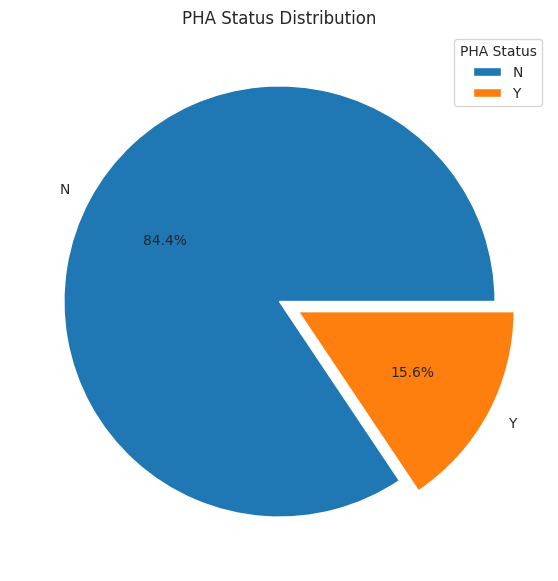

In [ ]:
pha_counts = df["PHA"].value_counts()
labels = pha_counts.index.tolist()
explode = [0.1 if label == "Y" else 0 for label in labels]

plt.figure(figsize=(7, 7))
plt.pie(pha_counts, labels=labels, autopct="%1.1f%%", explode=explode)
plt.title("PHA Status Distribution")
plt.legend(labels, title="PHA Status")
plt.show()


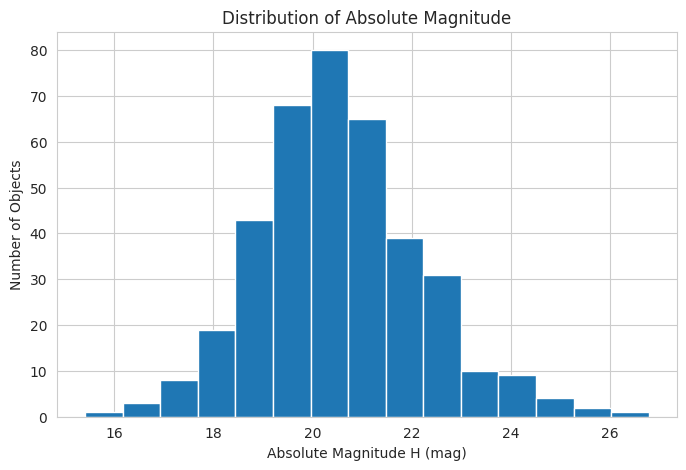

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["H (mag)"].dropna(), bins=15)
plt.title("Distribution of Absolute Magnitude")
plt.xlabel("Absolute Magnitude H (mag)")
plt.ylabel("Number of Objects")
plt.show()


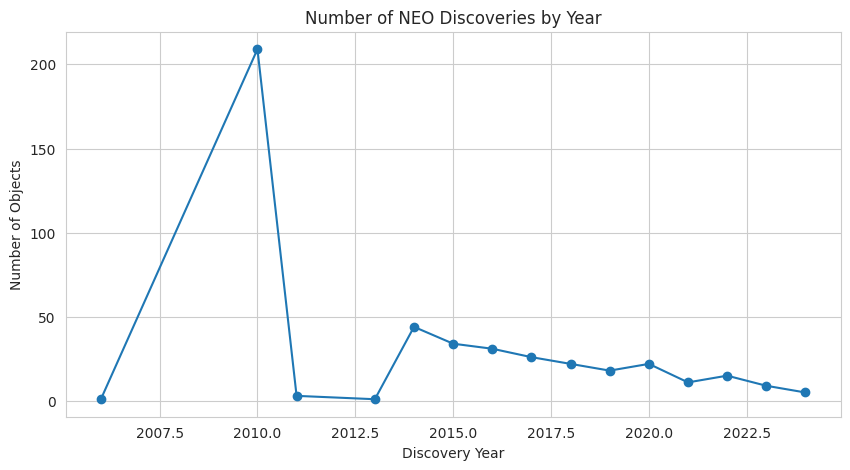

In [ ]:
year_counts = df["Discovery_Year"].value_counts().sort_index()

year_counts.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Number of NEO Discoveries by Year")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Objects")
plt.show()


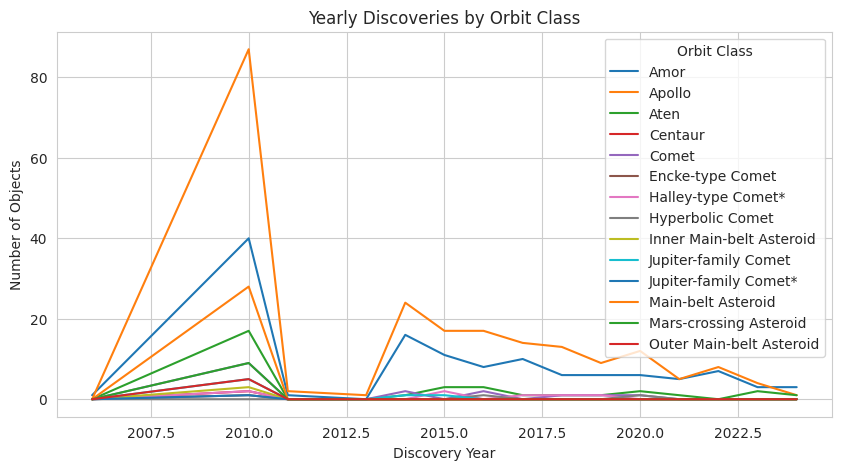

In [ ]:
year_class = df.groupby(["Discovery_Year", "Orbit Class"]).size().unstack(fill_value=0)

year_class.plot(figsize=(10, 5))
plt.title("Yearly Discoveries by Orbit Class")
plt.xlabel("Discovery Year")
plt.ylabel("Number of Objects")
plt.legend(title="Orbit Class")
plt.show()


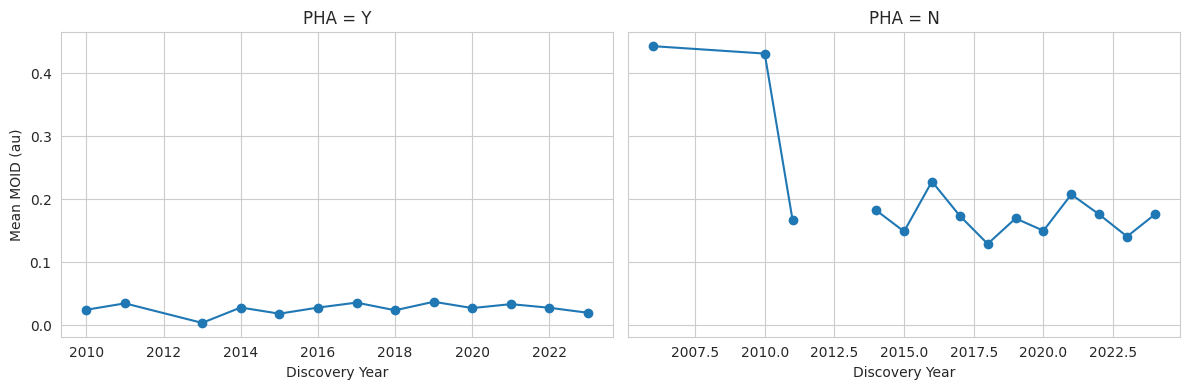

In [ ]:
known_pha = df[df["PHA"].isin(["Y", "N"])]
moid_by_year = known_pha.groupby(["Discovery_Year", "PHA"])["MOID (au)"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

if "Y" in moid_by_year.columns:
    moid_by_year["Y"].plot(ax=axes[0], marker="o")
axes[0].set_title("PHA = Y")
axes[0].set_xlabel("Discovery Year")
axes[0].set_ylabel("Mean MOID (au)")

if "N" in moid_by_year.columns:
    moid_by_year["N"].plot(ax=axes[1], marker="o")
axes[1].set_title("PHA = N")
axes[1].set_xlabel("Discovery Year")
axes[1].set_ylabel("Mean MOID (au)")

plt.tight_layout()
plt.show()


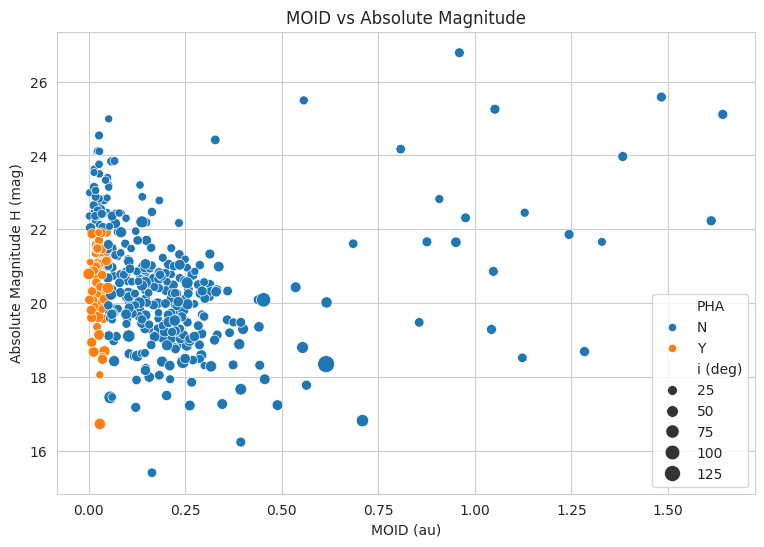

In [ ]:
scatter_data = df.dropna(subset=["MOID (au)", "H (mag)", "i (deg)", "PHA"])

plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_data, x="MOID (au)", y="H (mag)",
                hue="PHA", size="i (deg)", sizes=(30, 150))
plt.title("MOID vs Absolute Magnitude")
plt.xlabel("MOID (au)")
plt.ylabel("Absolute Magnitude H (mag)")
plt.show()


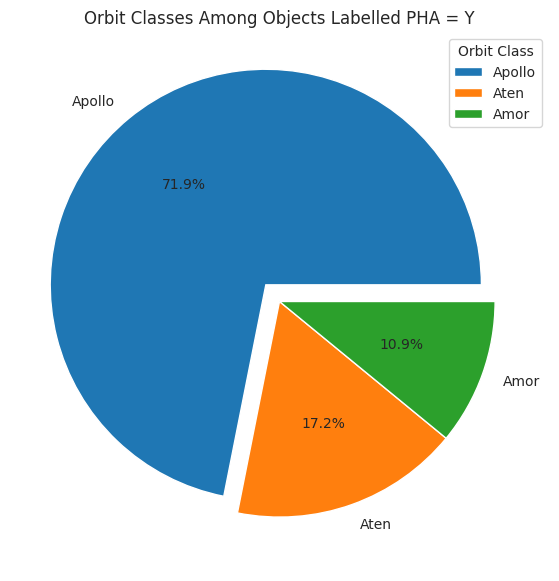

In [ ]:
pha_yes = df[df["PHA"] == "Y"]
pha_class_counts = pha_yes["Orbit Class"].value_counts()

if len(pha_class_counts) > 0:
    labels = pha_class_counts.index.tolist()
    explode = [0.1] + [0] * (len(labels) - 1)

    plt.figure(figsize=(8, 7))
    plt.pie(pha_class_counts, labels=labels, autopct="%1.1f%%", explode=explode)
    plt.title("Orbit Classes Among Objects Labelled PHA = Y")
    plt.legend(labels, title="Orbit Class")
    plt.show()


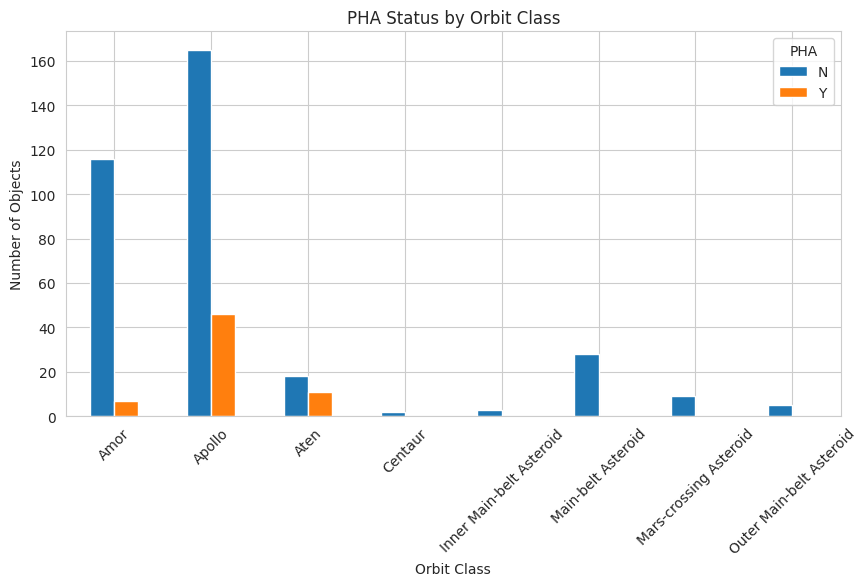

In [ ]:
pha_orbit_counts = pd.crosstab(df["Orbit Class"], df["PHA"])
pha_orbit_counts.plot(kind="bar", figsize=(10, 5))

plt.title("PHA Status by Orbit Class")
plt.xlabel("Orbit Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)
plt.show()


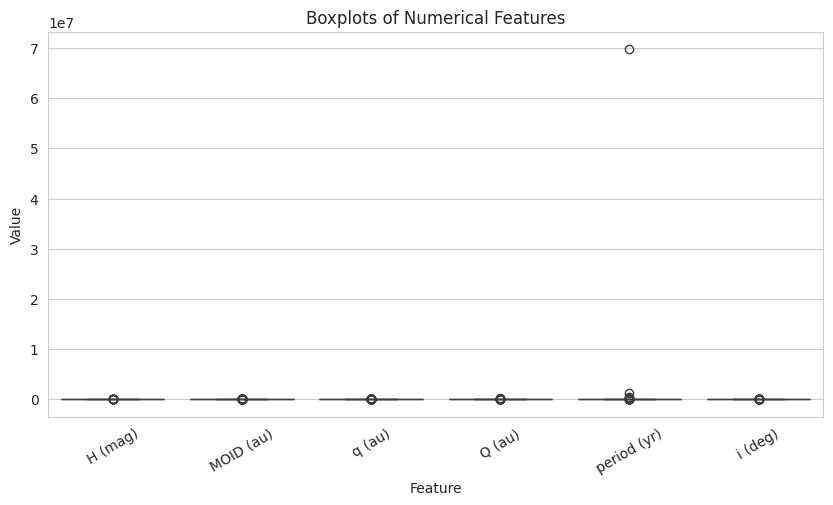

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[numeric_cols])
plt.title("Boxplots of Numerical Features")
plt.xlabel("Feature")
plt.ylabel("Value")
plt.xticks(rotation=30)
plt.show()


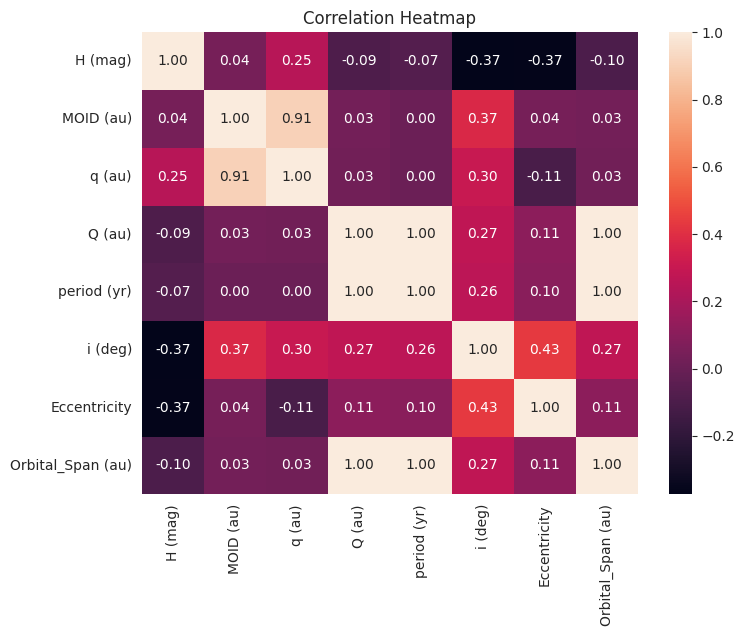

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


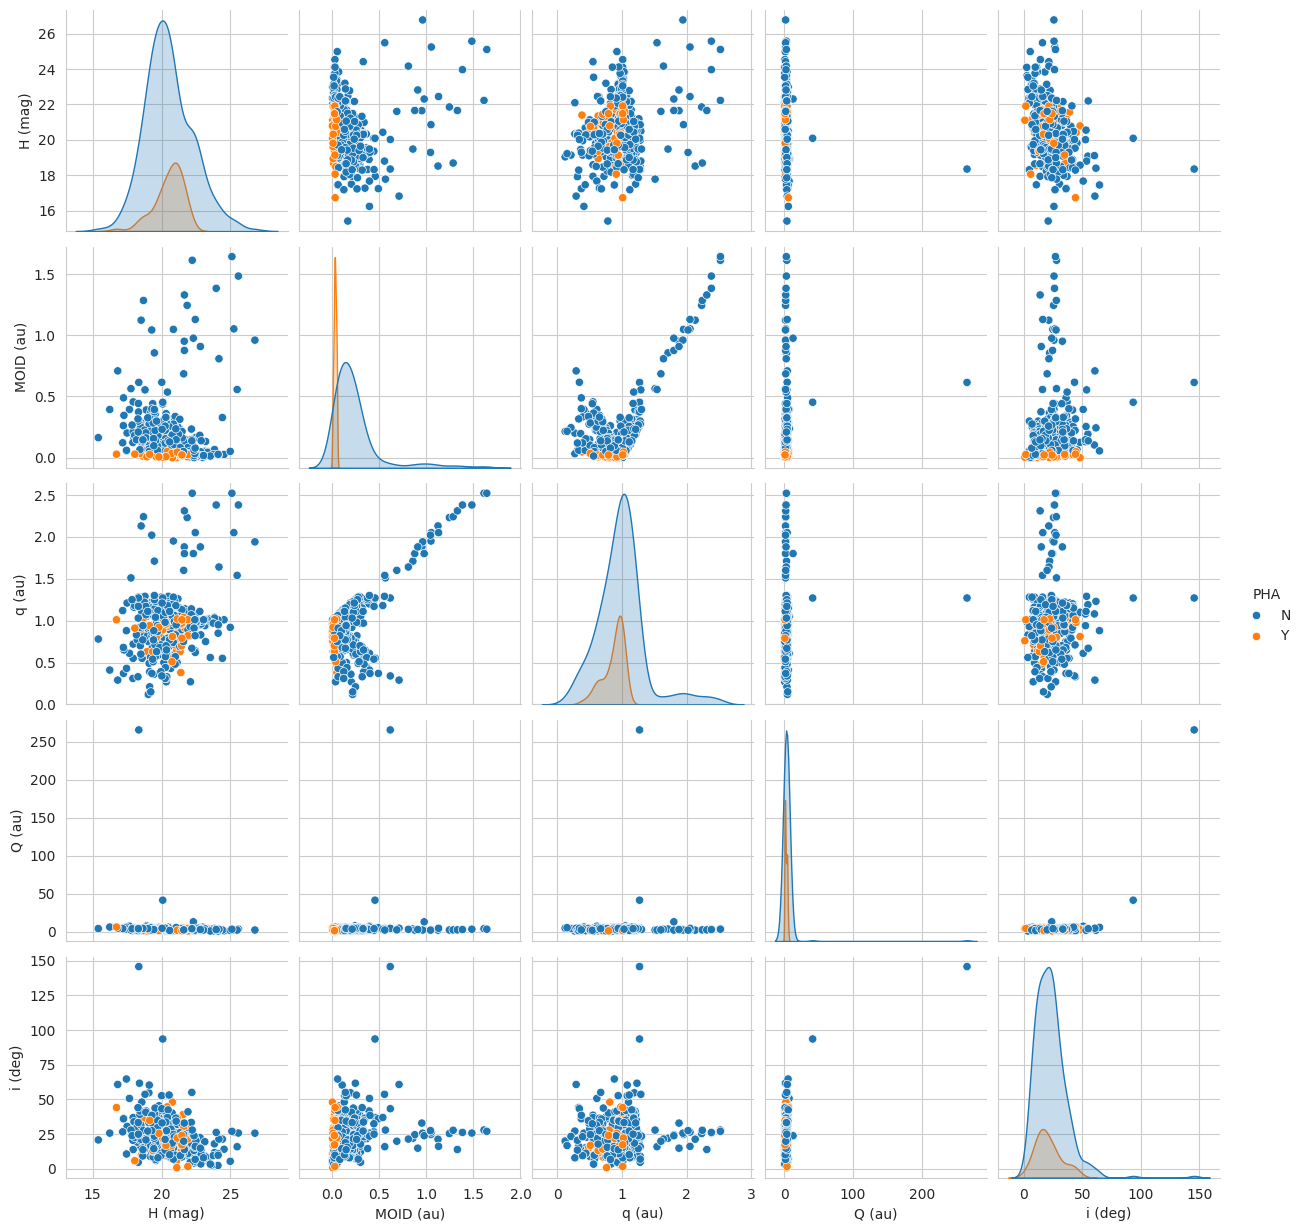

In [ ]:
pair_cols = ["H (mag)", "MOID (au)", "q (au)", "Q (au)", "i (deg)", "PHA"]
pair_df = df[pair_cols].dropna()

sns.pairplot(pair_df, vars=pair_cols[:-1], hue="PHA")
plt.show()


In [ ]:
# Screening filter for observation tracking only.
# This does NOT calculate impact probability.

screening_df = df[(df["MOID (au)"] <= 0.05) & (df["H (mag)"] <= 22)]
screening_df = screening_df.sort_values("MOID (au)")

print("Objects meeting both screening filters:", len(screening_df))
screening_df[["Designation", "H (mag)", "MOID (au)", "PHA", "Orbit Class"]].head(20)


Objects meeting both screening filters: 66


,Designation,H (mag),MOID (au),PHA,Orbit Class
287,(2010 MU112),20.79,0.0003,Y,Apollo
57,(2020 JU),20.83,0.0020,Y,Aten
366,436329 (2010 GX62),20.09,0.0020,Y,Apollo
237,(2013 YP139),21.11,0.0040,Y,Apollo
412,445305 (2010 DM56),19.81,0.0070,Y,Apollo
351,395207 (2010 HQ80),19.61,0.0080,Y,Apollo
225,(2014 HQ124),18.94,0.0080,Y,Aten
99,(2018 EB),21.88,0.0090,Y,Apollo
410,(2010 DG77),20.32,0.0090,Y,Apollo
155,(2016 BC14),20.98,0.0120,Y,Aten


In [ ]:
print("Number of records:", len(df))
print("Number of orbit classes:", df["Orbit Class"].nunique())
print("PHA = Y:", (df["PHA"] == "Y").sum())
print("PHA = N:", (df["PHA"] == "N").sum())
print("Unknown PHA:", df["PHA"].isna().sum())
print("Minimum MOID (au):", df["MOID (au)"].min())
print("Maximum MOID (au):", df["MOID (au)"].max())


Number of records: 451
Number of orbit classes: 14
PHA = Y: 64
PHA = N: 346
Unknown PHA: 41
Minimum MOID (au): 0.0003
Maximum MOID (au): 6.373


**Important:** The MOID and absolute-magnitude cut-offs are only a close-approach screening filter for observation tracking. They do not calculate impact probability.